# 05 · Stern–Gerlach (1921–1927)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasonDE03/sophon/blob/main/lab/05_stern_gerlach.ipynb)

Ước lượng độ lệch, dựng tấm kính, rồi kiểm tra các bộ lọc spin. Chạy từ trên xuống; không cần tải dữ liệu.
*Estimate the deflection, build the plate, then test spin filters. Run from top to bottom; no data downloads are needed.*

## 1. Độ lệch / Deflection

$F_z=\mu_z G$, $t=L/v$, $z=\mu_z G L^2/(2mv^2)$. Đặt tấm kính ngay sau nam châm, bỏ qua đoạn bay tự do phía sau. Với chùm effusive (khí thoát qua lỗ nhỏ), $\langle E\rangle=2k_BT$, nên $\langle v^2\rangle=4k_BT/m$.
*The plate is placed at the magnet exit, omitting further free flight. An effusive beam has mean kinetic energy $2k_BT$, hence mean squared speed $4k_BT/m$.*

Bảng dùng tốc độ hiệu dụng: $z(\langle v^2\rangle)$, không phải độ lệch trung bình $\langle z\rangle$ của cả phân bố. Hằng số lấy từ SciPy; khối lượng bạc là 107,8682 u.
*The table uses the effective speed: $z(\langle v^2\rangle)$, not the distribution's mean deflection $\langle z\rangle$. Constants come from SciPy; silver has mass 107.8682 u.*

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import k, atomic_mass, physical_constants
from IPython.display import display, Markdown

mass = 107.8682 * atomic_mass
mu_B = physical_constants["Bohr magneton"][0]
L = 0.035  # m; the plate is at the magnet exit.

def beam_speed_sq(T):
    return 4 * k * T / mass

def deflection(mu_z, gradient, length, v2):
    return mu_z * gradient * length**2 / (2 * mass * v2)

def table(headers, rows):
    display(Markdown("| " + " | ".join(headers) + " |\n| " + " | ".join(["---"] * len(headers)) + " |\n" +
                     "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)))

estimate = deflection(mu_B, 1000, L, beam_speed_sq(1300))
assert abs(estimate / 7.9e-5 - 1) < .05
print(f"Silver mass: {mass:.8e} kg; Bohr magneton: {mu_B:.10e} J/T")
print(f"Effective speed at 1300 K: {np.sqrt(beam_speed_sq(1300)):.2f} m/s")
print(f"One-sided deflection: {estimate:.8e} m = {estimate * 1e3:.5f} mm")
table(["T (K)", "Gradient (T/m)", "Effective speed (m/s)", "One-sided z (mm)"],
      [[T, G, f"{np.sqrt(beam_speed_sq(T)):.2f}",
        f"{deflection(mu_B, G, L, beam_speed_sq(T)) * 1e3:.5f}"]
       for T in [1100, 1300, 1500] for G in [500, 1000, 1400]])

Silver mass: 1.79119360e-25 kg; Bohr magneton: 9.2740100657e-24 J/T
Effective speed at 1300 K: 633.10 m/s
One-sided deflection: 7.91201368e-05 m = 0.07912 mm


| T (K) | Gradient (T/m) | Effective speed (m/s) | One-sided z (mm) |
| --- | --- | --- | --- |
| 1100 | 500 | 582.37 | 0.04675 |
| 1100 | 1000 | 582.37 | 0.09351 |
| 1100 | 1400 | 582.37 | 0.13091 |
| 1300 | 500 | 633.10 | 0.03956 |
| 1300 | 1000 | 633.10 | 0.07912 |
| 1300 | 1400 | 633.10 | 0.11077 |
| 1500 | 500 | 680.06 | 0.03429 |
| 1500 | 1000 | 680.06 | 0.06857 |
| 1500 | 1400 | 680.06 | 0.09600 |

## 2. Tấm kính / The glass plate

Với chùm effusive, $p(v)\propto v^3\exp[-mv^2/(2k_BT)]$, nên $u=mv^2/(2k_BT)$ có phân bố Gamma với shape 2, scale 1. Lấy mẫu đầy đủ, không cắt phân bố tốc độ. Vị trí dọc khe $x$ đều trên $[-1,1]$; gradient $G(x)=G_0(1-x^2)$ là mô hình đơn giản tạo hình “hai môi”, không phải phép dựng lại bản đồ từ trường lịch sử. Độ rộng khe được biểu diễn bằng nhiễu Gaussian 1,5 µm theo $z$.
*For an effusive beam, $u=mv^2/(2k_BT)$ follows Gamma(shape=2, scale=1). Sample the full speed distribution. Slit position $x$ is uniform on $[-1,1]$; $G(x)=G_0(1-x^2)$ is a simple lip-shaped field model, not a reconstruction of the historical field map. Gaussian noise of 1.5 µm in $z$ represents slit width.*

Cổ điển: $\cos\theta$ đều trên $[-1,1]$; lượng tử: $\mu_z=\pm\mu_B$. Chấm là từng nguyên tử, không phải đường quỹ đạo. Các nguyên tử chậm lệch xa có thể nằm ngoài khung hình; phần trăm hiển thị được in bên dưới. Mô phỏng web dùng độ trải tốc độ hẹp hơn để dễ thấy hai vệt.
*Classical: uniform $\cos\theta$; quantum: $\mu_z=\pm\mu_B$. Dots represent deposited atoms, not trajectories. Slow atoms with large deflections can fall outside the plot; the visible fraction is printed below. The web simulation uses a narrower speed spread to make the two traces easier to see.*

Classical: continuous band: 97.98% of deposits inside displayed window
Quantum: two lips: 94.39% of deposits inside displayed window


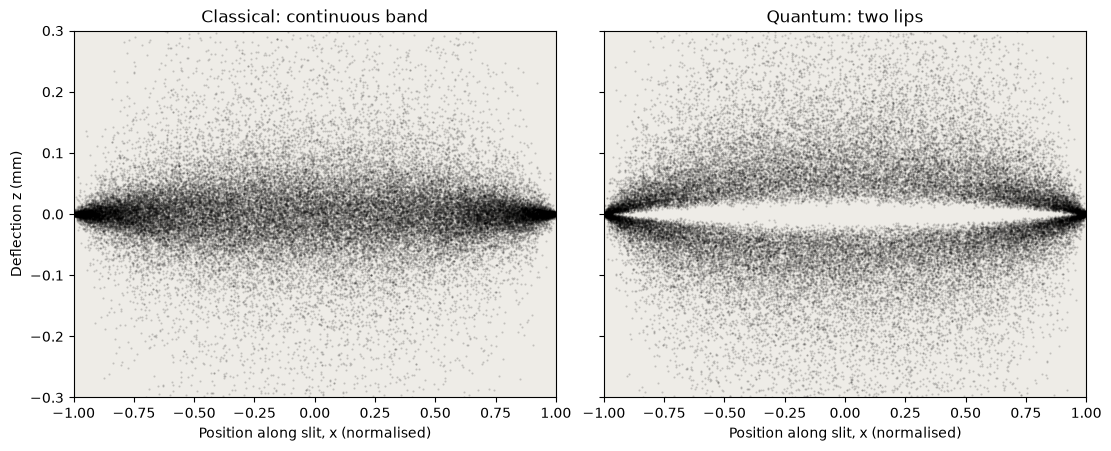

Mean |quantum deflection| at slit centre (analytic): 0.15824 mm


In [2]:
rng = np.random.default_rng(1922)
N, T, G = 50000, 1300, 1000
x = rng.uniform(-1, 1, N)
u = rng.gamma(shape=2, scale=1, size=N)
v2 = 2 * k * T / mass * u
assert abs(np.mean(v2) / beam_speed_sq(T) - 1) < .015
profile = lambda x: 1 - x**2
assert profile(0) == 1 and profile(-1) == profile(1) == 0
blur = rng.normal(0, 1.5e-6, N)
mu_classical = mu_B * rng.uniform(-1, 1, N)
mu_quantum = mu_B * rng.choice([-1, 1], N)
plates = [deflection(mu, G * profile(x), L, v2) + blur for mu in [mu_classical, mu_quantum]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, layout="constrained")
for ax, z, title in zip(axes, plates, ["Classical: continuous band", "Quantum: two lips"]):
    ax.set_facecolor("#eeece7")
    ax.scatter(x, z * 1e3, s=.3, c="black", alpha=.16, rasterized=True)
    ax.set(xlim=(-1, 1), ylim=(-.3, .3), xlabel="Position along slit, x (normalised)", title=title)
    print(f"{title}: {np.mean(abs(z) < .3e-3):.2%} of deposits inside displayed window")
axes[0].set_ylabel("Deflection z (mm)")
plt.show()
# For this full distribution, <1/v²> = m/(2kT); it is not 1/<v²>.
print(f"Mean |quantum deflection| at slit centre (analytic): {2 * estimate * 1e3:.5f} mm")

## 3. Spin-½ và bộ lọc / Spin-½ and filters

Trong mặt phẳng $xz$, $\mathbf n=(\sin\alpha,0,\cos\alpha)$ và $P_\pm=(I\pm\mathbf n\cdot\boldsymbol\sigma)/2$. Với trạng thái đầu $|\uparrow_z\rangle$, xác suất $\langle\uparrow_z|P_+|\uparrow_z\rangle=\cos^2(\alpha/2)$.
*In the $xz$ plane, use the Pauli matrices to form the projectors above. For a prepared $z$-up state, the probability of the plus outcome is $\cos^2(\alpha/2)$.*

Bắt đầu bằng chùm đã chuẩn bị $z$-up, như trong sim. Ở mỗi bộ lọc trừ bộ cuối, chặn cổng thứ hai. Vì thế chùm $z\to x\to z$ cho $1/2\times1/2=1/4$ chùm đầu vào ở cổng cuối “xuống”; đó là một nửa chùm đi vào nam châm cuối. Nếu nguồn chưa phân cực, bộ lọc $z$ đầu tiên còn loại một nửa, cho $1/8$ toàn bộ nguồn.
*Start with a prepared $z$-up beam, as in the web simulation. Block the second output of every filter except the last. The final down port receives one quarter of that prepared input, or half the beam entering the last magnet. An unpolarised source would lose another half at the first $z$ filter, giving one eighth of the full source.*

In [3]:
I = np.eye(2, dtype=complex)
sigma_x = np.array([[0, 1], [1, 0]], dtype=complex)
sigma_y = np.array([[0, -1j], [1j, 0]], dtype=complex)
sigma_z = np.array([[1, 0], [0, -1]], dtype=complex)
z_up = np.array([1, 0], dtype=complex)

def projectors(alpha):
    sigma_n = np.sin(alpha) * sigma_x + np.cos(alpha) * sigma_z
    return (I + sigma_n) / 2, (I - sigma_n) / 2

def probability(state, projector):
    return float(np.vdot(state, projector @ state).real)

angles = np.linspace(0, np.pi, 101)
for alpha in angles:
    plus, minus = projectors(alpha)
    assert np.allclose(plus @ plus, plus)
    assert np.allclose(plus @ minus, 0)
    assert np.allclose(plus + minus, I)
    assert np.isclose(probability(z_up, plus), np.cos(alpha / 2)**2, atol=1e-12)
for sigma in [sigma_x, sigma_y, sigma_z]:
    assert np.allclose(sigma @ sigma, I)
table(["Angle (degrees)", "Projector probability", "cos²(α/2)"],
      [[a, f"{probability(z_up, projectors(np.deg2rad(a))[0]):.12f}",
        f"{np.cos(np.deg2rad(a) / 2)**2:.12f}"] for a in [0, 90, 180]])

shots = 100000
survivors, state = shots, z_up.copy()
rows = []
for i, alpha in enumerate([0, np.pi / 2, 0]):
    plus, minus = projectors(alpha)
    p_plus = probability(state, plus)
    up = int(np.count_nonzero(rng.random(survivors) < p_plus))
    down = survivors - up
    rows.append([['z', 'x', 'z'][i], survivors, up, down, f"{down / survivors:.3%}"])
    if i < 2:
        state = plus @ state / np.sqrt(p_plus)
        survivors = up
    else:
        final_down = down
assert abs(final_down / shots - .25) < .005
P_z_up, P_z_down = projectors(0)
P_x_up, _ = projectors(np.pi / 2)
# Unnormalised amplitude includes loss at the blocked x-down port.
amplitude = P_z_down @ P_x_up @ P_z_up @ z_up
assert np.isclose(np.vdot(amplitude, amplitude).real, .25, atol=1e-12)
table(["Magnet", "Input", "Plus output", "Minus output", "Minus / local input"], rows)
print(f"Final down / prepared original beam: {final_down / shots:.3%} (theory: 25%)")

| Angle (degrees) | Projector probability | cos²(α/2) |
| --- | --- | --- |
| 0 | 1.000000000000 | 1.000000000000 |
| 90 | 0.500000000000 | 0.500000000000 |
| 180 | 0.000000000000 | 0.000000000000 |

| Magnet | Input | Plus output | Minus output | Minus / local input |
| --- | --- | --- | --- | --- |
| z | 100000 | 100000 | 0 | 0.000% |
| x | 100000 | 50106 | 49894 | 49.894% |
| z | 50106 | 25107 | 24999 | 49.892% |

Final down / prepared original beam: 24.999% (theory: 25%)


## 4. Đúng kết quả, sai lý do / Right result, wrong reason

Năm 1922, Stern và Gerlach diễn giải hai vệt là lượng tử hoá hướng của quỹ đạo trong mô hình Bohr–Sommerfeld. Electron ngoài cùng của bạc thực ra có mômen động lượng quỹ đạo bằng không: hai vệt đến từ spin, được đề xuất năm 1925. Thí nghiệm Phipps–Taylor với hydro năm 1927 giúp làm rõ cách hiểu này. Các bộ lọc nối tiếp ở trên là thí nghiệm tưởng tượng về sau, không phải bố trí năm 1922.
*In 1922, Stern and Gerlach interpreted the two traces as orbital space quantisation in the Bohr–Sommerfeld model. Silver’s outermost electron actually has zero orbital angular momentum: the splitting comes from spin, proposed in 1925. Phipps and Taylor’s 1927 hydrogen experiment helped clarify this interpretation. The sequential filters above are a later thought experiment, not the 1922 apparatus.*

Nguồn / Sources: T. E. Phipps & J. B. Taylor, *Phys. Rev.* **29**, 309 (1927); B. Friedrich & D. Herschbach, *Physics Today* **56**(12), 53 (2003); H. Schmidt-Böcking et al., *Eur. Phys. J. H* **41**, 327 (2016).

## 5. Thử thêm / Try this

- Tăng $L$ gấp đôi, hoặc $T$ gấp đôi: độ lệch thay đổi thế nào?
  *Double $L$, or double $T$: how does the deflection change?*
- Thay $1-x^2$ bằng gradient đều: hai môi biến thành hình gì? Tắt nam châm bằng $G=0$.
  *Replace $1-x^2$ with a uniform gradient: what replaces the lips? Switch the magnet off with $G=0$.*
- Giảm độ rộng khe, so sánh phân bố effusive đầy đủ với độ trải $v^2$ ±20% quanh giá trị hiệu dụng.
  *Reduce slit width and compare the full effusive distribution with a ±20% spread in $v^2$ around its effective value.*
- Xoay nam châm giữa một góc $\alpha$: chứng minh phần chùm đầu vào ra cổng “xuống” cuối bằng $\cos^2(\alpha/2)\sin^2(\alpha/2)$.
  *Rotate the middle magnet by $\alpha$: show that the fraction of the prepared original beam reaching the final down port is $\cos^2(\alpha/2)\sin^2(\alpha/2)$.*